In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
plt.style.use('seaborn-v0_8-whitegrid')
RANDOM_STATE = 42

data_train = pd.read_csv('data_train.csv')
target_train = pd.read_csv('target_train.csv')
data_test = pd.read_csv('data_test_small.csv')
target_test = pd.read_csv('target_test_small.csv')

print("Размеры датасетов:")
print(f"data_train: {data_train.shape}")
print(f"target_train: {target_train.shape}")
print(f"data_test: {data_test.shape}")
print(f"target_test: {target_test.shape}\n")

Размеры датасетов:
data_train: (319546, 17)
target_train: (1773, 2)
data_test: (39943, 17)
target_test: (318, 2)



In [3]:
# приведение времени
def get_time_col(df):
    for col in df.columns:
        low = str(col).lower()
        if any(k in low for k in ['time', 'date', 'ts', 'unnamed', 'дата', 'время']):
            return col
    return df.columns[0]

t_col_data = get_time_col(data_train)
t_col_target = get_time_col(target_train)

for df, col in [(data_train, t_col_data), (data_test, t_col_data),
                (target_train, t_col_target), (target_test, t_col_target)]:
    df[col] = pd.to_datetime(df[col])
    df.sort_values(col, inplace=True)
    df.reset_index(drop=True, inplace=True)

print("Временные границы:")
print(f"train телеметрия: {data_train[t_col_data].min()} - {data_train[t_col_data].max()}")
print(f"train таргет: {target_train[t_col_target].min()} - {target_train[t_col_target].max()}")
print(f"test телеметрия: {data_test[t_col_data].min()} - {data_test[t_col_data].max()}")
print(f"test таргет: {target_test[t_col_target].min()} - {target_test[t_col_target].max()}\n")

# пропуски и типы
print("Пропуски в data_train:")
null_summary = pd.DataFrame({
    'dtype': data_train.dtypes,
    'null_count': data_train.isnull().sum(),
    'null_pct': (data_train.isnull().mean() * 100).round(2),
})
display(null_summary)

print("\nПропуски в target_train:")
display(pd.DataFrame({
    'dtype': target_train.dtypes,
    'null_count': target_train.isnull().sum(),
    'null_pct': (target_train.isnull().mean() * 100).round(2),
}))

# описательные статистики
print("\nОписательные статистики target_train:")
display(target_train.select_dtypes(include=[np.number]).describe().T.round(4))

print("\nОписательные статистики телеметрии:")
num_cols = data_train.select_dtypes(include=[np.number]).columns.tolist()
display(data_train[num_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(3))

Временные границы:
train телеметрия: 2019-03-01 00:01:00 - 2019-10-07 19:58:00
train таргет: 2019-03-13 17:00:00 - 2019-10-07 21:00:00
test телеметрия: 2019-10-07 19:59:00 - 2019-11-04 10:25:00
test таргет: 2019-10-07 23:00:00 - 2019-11-04 09:00:00

Пропуски в data_train:


,dtype,null_count,null_pct
datetime,datetime64[ns],0,0.0000
telemetry_0,float64,17,0.0100
telemetry_1,float64,16,0.0100
telemetry_2,float64,16,0.0100
telemetry_3,float64,16,0.0100
telemetry_4,float64,133,0.0400
telemetry_5,float64,17,0.0100
telemetry_6,float64,16,0.0100
telemetry_7,float64,16,0.0100
telemetry_8,float64,16,0.0100



Пропуски в target_train:


,dtype,null_count,null_pct
Дата,datetime64[ns],0,0.0000
target,float64,0,0.0000



Описательные статистики target_train:


,count,mean,std,min,25%,50%,75%,max
target,1773.0000,0.2543,0.0922,0.0000,0.1753,0.2474,0.3144,0.7165



Описательные статистики телеметрии:


,count,mean,std,min,50%,max
telemetry_0,319529.0000,0.6100,0.2760,0.0030,0.7390,1.0000
telemetry_1,319530.0000,0.3800,0.1980,0.0000,0.4860,0.6110
telemetry_2,319530.0000,0.2670,0.0880,0.0320,0.2960,1.0000
telemetry_3,319530.0000,0.5200,0.2590,0.0000,0.6390,1.0000
telemetry_4,319413.0000,0.7620,0.3260,0.0000,0.9190,1.0000
telemetry_5,319529.0000,0.6960,0.2840,0.0000,0.8300,1.0000
telemetry_6,319530.0000,0.5940,0.3000,0.0000,0.7490,1.0000
telemetry_7,319530.0000,0.5230,0.2530,0.0210,0.4110,1.0000
telemetry_8,319530.0000,0.4700,0.0240,0.3440,0.4680,1.0000
telemetry_9,319530.0000,0.5360,0.2550,0.0000,0.5820,1.0000


данные - 16 датчиков телеметрии с минутным шагом (319 546 строк за 8 месяцев), 1773 лабораторных замера target.  
train - март–октябрь 2019, test - октябрь–ноябрь 2019 (без пересечения).

target (концентрация продукта): mean = 0.254, std = 0.092, диапазон [0, 0.716]. распределение далеко от нормального.  

12 датчиков (telemetry_0..11) - минутные, пропусков 0.01-0.04%.

4 датчика (telemetry_12..15) - заполнены на 0.66% (замеры раз в 2 часа).

нерегулярность target (120 мин) и 2-часовых датчиков требует единой минутной сетки для корректных лагов.

In [4]:
print("Дубликаты datetime:")
print(f"data_train: {data_train['datetime'].duplicated().sum()}")
print(f"data_test: {data_test['datetime'].duplicated().sum()}")
print(f"target_train: {target_train['Дата'].duplicated().sum()}")
print(f"target_test: {target_test['Дата'].duplicated().sum()}\n")

# проверка расхождений внутри дубликатов
dup_mask = data_train['datetime'].duplicated(keep=False)
dups = data_train.loc[dup_mask].sort_values('datetime')
num_dup = [c for c in data_train.columns if c.startswith('telemetry_')]
max_unique = dups.groupby('datetime')[num_dup].nunique().max(axis=1).max()
print(f"Макс. число разных значений одного датчика внутри дубликата: {max_unique}")

# разрывы шага телеметрии
dt_series = data_train['datetime'].reset_index(drop=True)
dt_diffs  = dt_series.diff()
gap_gt_1m = dt_diffs[dt_diffs > pd.Timedelta(minutes=1)]
print(f"\nРазрывов шага телеметрии > 1 мин: {len(gap_gt_1m)}")
if len(gap_gt_1m) > 0:
    gap_idx = gap_gt_1m.index
    gaps_df = pd.DataFrame({
        'prev_dt': dt_series.shift(1).loc[gap_idx].values,
        'curr_dt': dt_series.loc[gap_idx].values,
        'gap_min': (gap_gt_1m.dt.total_seconds() / 60.0).values,
    })
    display(gaps_df.sort_values('gap_min', ascending=False).head(10))

# регулярность 2-часовых датчиков
sparse_cols = ['telemetry_12', 'telemetry_13', 'telemetry_14', 'telemetry_15']
non_sparse  = data_train.dropna(subset=sparse_cols, how='all')
print(f"\ntelemetry_12..15: {len(non_sparse)} непустых строк")
print(f"диапазон: {non_sparse['datetime'].min()} - {non_sparse['datetime'].max()}")

Дубликаты datetime:
data_train: 1548
data_test: 196
target_train: 0
target_test: 0

Макс. число разных значений одного датчика внутри дубликата: 2

Разрывов шага телеметрии > 1 мин: 0

telemetry_12..15: 2098 непустых строк
диапазон: 2019-03-01 02:00:00 - 2019-10-07 18:00:00


In [5]:
sparse_dt = non_sparse['datetime'].diff().dropna()
print("\nИнтервалы между замерами (мин), топ-5:")
print((sparse_dt.dt.total_seconds() / 60.0).value_counts().head(5))

# интервалы между лабораторными замерами
dt_target_min = target_train['Дата'].diff().dropna().dt.total_seconds() / 60.0
print("\nИнтервалы между target-замерами (мин):")
print(dt_target_min.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2))


Интервалы между замерами (мин), топ-5:
datetime
120.0000    2071
240.0000      11
360.0000       2
840.0000       1
600.0000       1
Name: count, dtype: int64

Интервалы между target-замерами (мин):
count    1772.0000
mean      169.1600
std       784.0900
min        60.0000
5%        120.0000
25%       120.0000
50%       120.0000
75%       120.0000
95%       240.0000
max     26430.0000
Name: Дата, dtype: float64


дубликаты datetime (1548 в train, 196 в test) больше похоже не на ошибки данных, а на одновременную запись от двух источников. расхождения внутри дубликата - не более 2 значений на датчик.  
Стратегия: groupby('datetime').mean().

Разрывов шага > 1 мин нет - минутная сетка непрерывна.  

telemetry_12..15: интервал 120 мин в 98.7% случаев (2071 из 2098). Остальные 27 - пропуски (240/360/600/840 мин), соответствующие остановкам замеров. Стратегия ffill(limit=180) заполнит только 3 часа (физически обоснованно - инерционность печи), а дальше оставит NaN.

Интервалы target:  
87% - 120 мин, 9% - 240 мин (пропуск замера), единичные разрывы до 18 суток (остановки производства). это надо учесть через какой-нибудь флаг

## 2.1 EDA: распределения, тренды, сезонность, выбросы

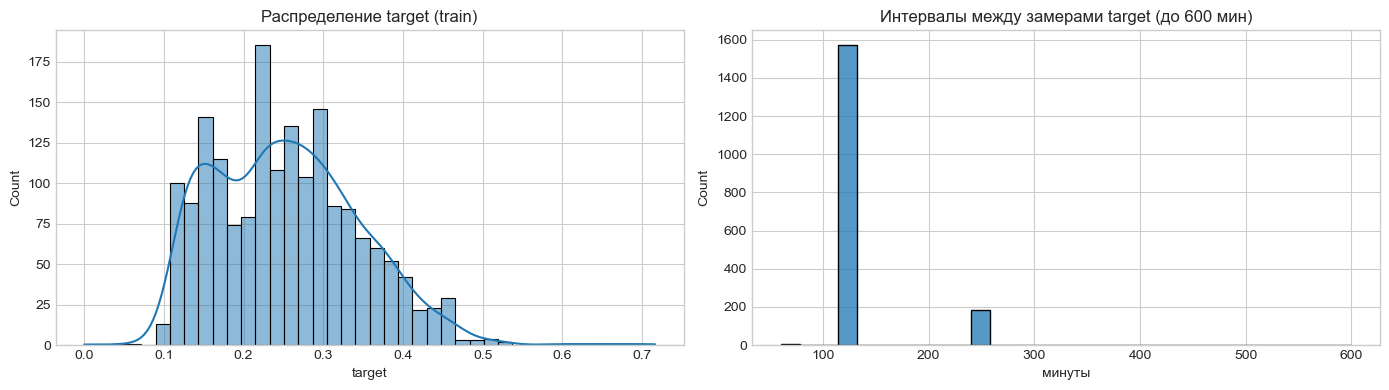

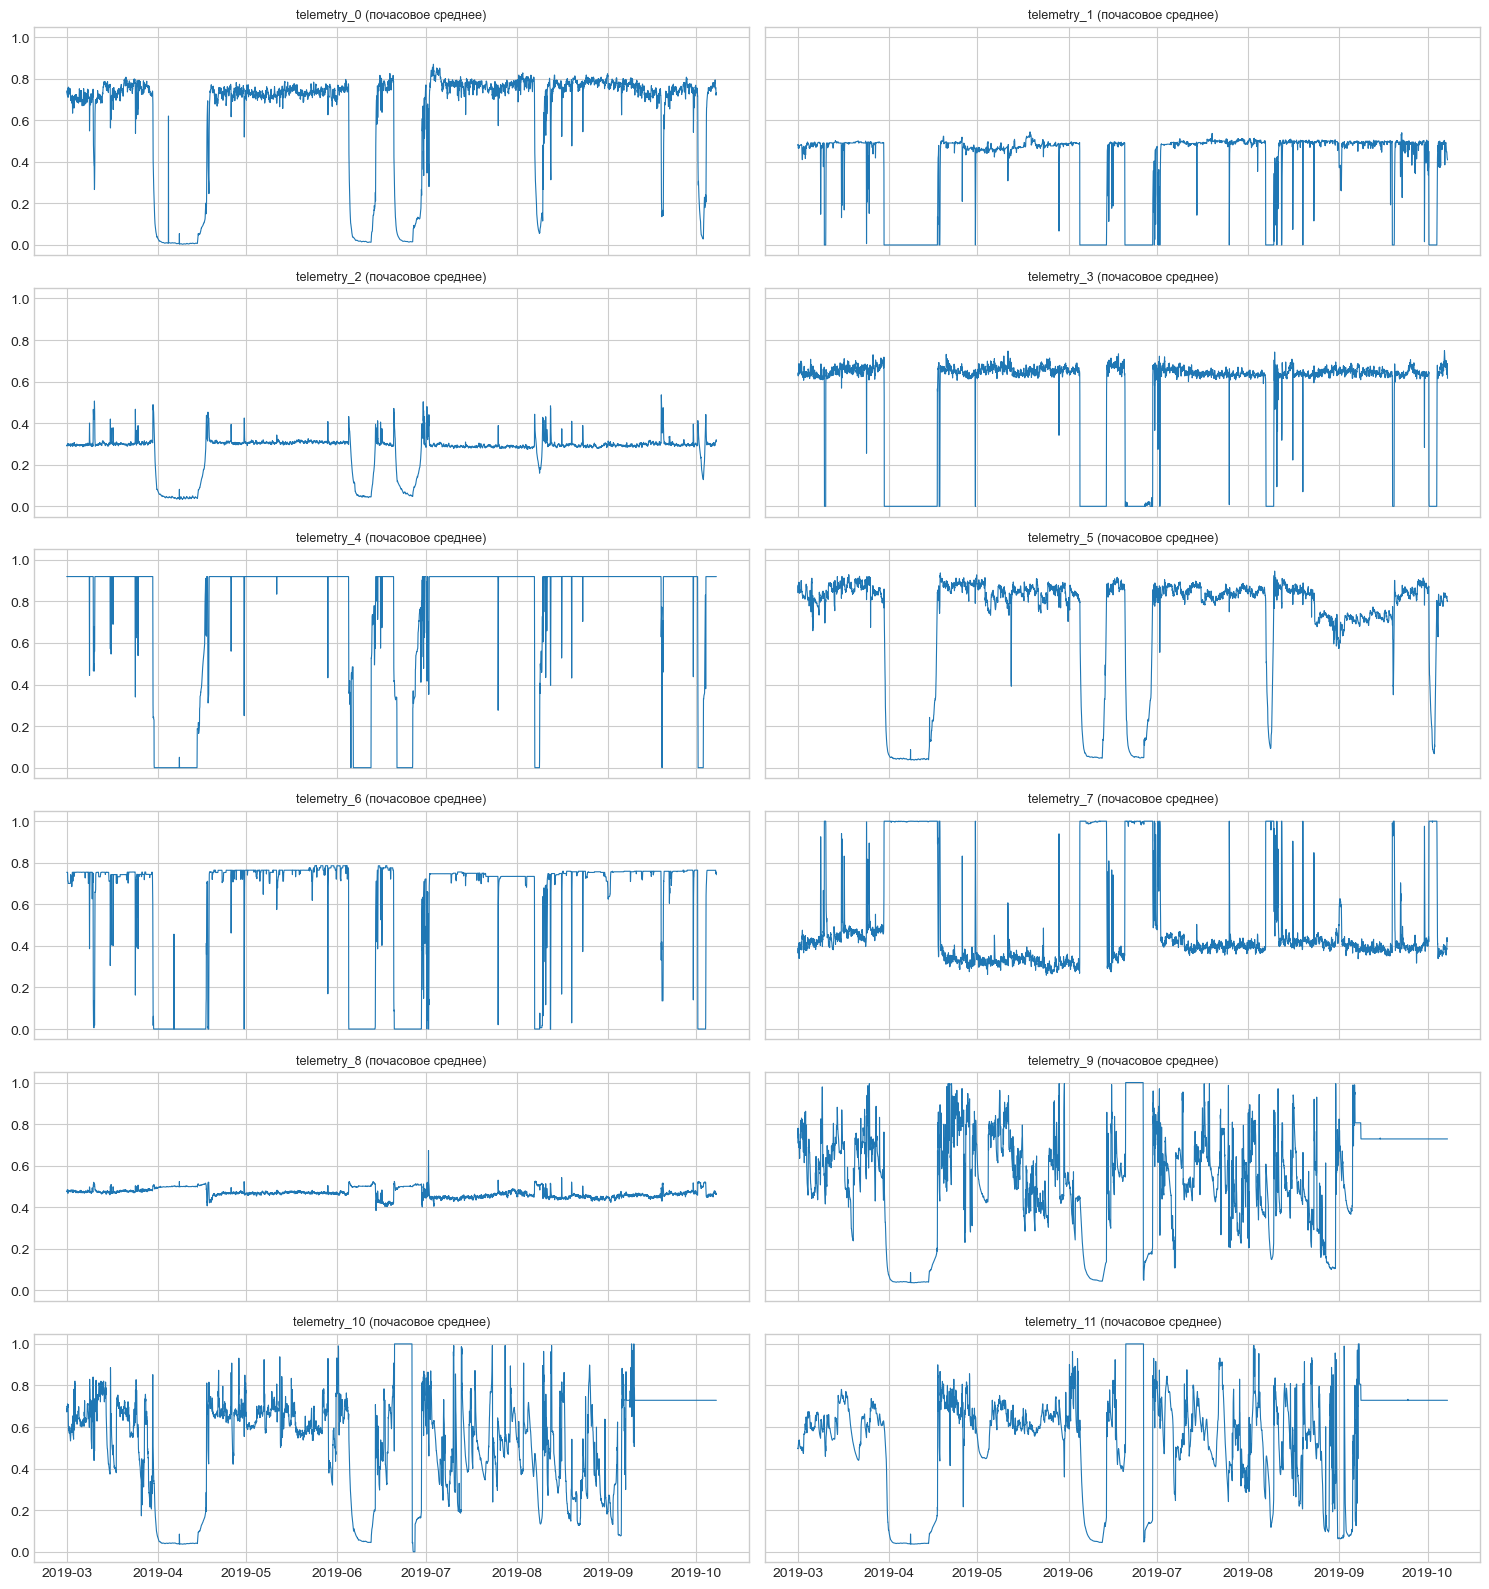

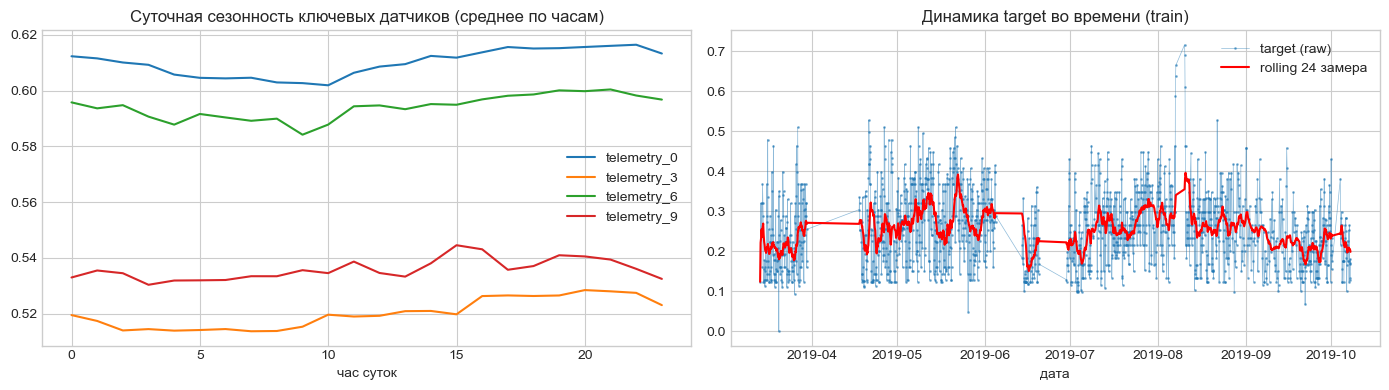

IQR-выбросы target: 8 из 1773 (0.5%)
  диапазон выбросов: [0.000, -0.034) ∪ (0.523, 0.716]

Примеры выбросов (первые 5):


,Дата,target
228,2019-04-21 01:00:00,0.5284
1253,2019-08-07 03:00:00,0.5876
1254,2019-08-07 05:00:00,0.6392
1255,2019-08-07 07:00:00,0.6649
1256,2019-08-10 09:00:00,0.7165


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(target_train['target'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Распределение target (train)')
axes[0].set_xlabel('target')

valid_dt = dt_target_min[dt_target_min <= 600]
sns.histplot(valid_dt, bins=30, kde=False, ax=axes[1])
axes[1].set_title('Интервалы между замерами target (до 600 мин)')
axes[1].set_xlabel('минуты')
plt.tight_layout(); plt.show()

# телеметрия (почасовое среднее)
ts_num = data_train.drop_duplicates('datetime').set_index('datetime').sort_index()
hourly_num = ts_num[[f'telemetry_{i}' for i in range(12)]].resample('1h').mean()

fig, axes = plt.subplots(6, 2, figsize=(15, 16), sharex=True, sharey=True)
axes = axes.ravel()
for i in range(12):
    axes[i].plot(hourly_num.index, hourly_num[f'telemetry_{i}'], linewidth=0.8)
    axes[i].set_title(f'telemetry_{i} (почасовое среднее)', fontsize=9)
plt.tight_layout(); plt.show()

# суточная сезонность (средние по часам суток)
ts_season = data_train.drop_duplicates('datetime').set_index('datetime').sort_index()
hourly_season = ts_season[[f'telemetry_{i}' for i in range(12)]].groupby(
    ts_season.index.hour).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
hourly_season[['telemetry_0', 'telemetry_3', 'telemetry_6', 'telemetry_9']].plot(ax=axes[0])
axes[0].set_title('Суточная сезонность ключевых датчиков (среднее по часам)')
axes[0].set_xlabel('час суток')

axes[1].plot(target_train['Дата'], target_train['target'],
             marker='.', markersize=2, linewidth=0.5, alpha=0.5, label='target (raw)')
axes[1].plot(target_train['Дата'],
             target_train['target'].rolling(24, min_periods=1).mean(),
             color='red', linewidth=1.5, label='rolling 24 замера')
axes[1].set_title('Динамика target во времени (train)')
axes[1].set_xlabel('дата'); axes[1].legend()
plt.tight_layout(); plt.show()

# -проверка выбросов
q1, q3 = np.percentile(target_train['target'], [25, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
outlier_mask = (target_train['target'] < lower) | (target_train['target'] > upper)
print(f"IQR-выбросы target: {outlier_mask.sum()} из {len(target_train)} "
      f"({100*outlier_mask.sum()/len(target_train):.1f}%)")
print(f"  диапазон выбросов: [{target_train['target'].min():.3f}, {lower:.3f}) "
      f"∪ ({upper:.3f}, {target_train['target'].max():.3f}]")
print("\nПримеры выбросов (первые 5):")
display(target_train[outlier_mask].head())

распределение target - бимодальное (пики на 0.13 и 0.23), с длинным правым хвостом до 0.71. это не нормальное распределение, что критично: MSE-регрессия будет тянуться к среднему и терять пики.  

интервалы: основной режим - 120 мин (87%), 240 мин - 9% (пропуск замера). гистограмма четко бимодальна.  

телеметрия: на почасовых графиках видны периодические провалы telemetry_4, 5, 6, 7 - вероятно штатные остановки печи (печь остывает). не выбросы! модель должна знать эти режимы печи.  

суточная сезонность: telemetry_0 и telemetry_6 имеют четкий суточный цикл (утром выше, к ночи падают). физически: печь разогревается к смене оператора.  

выбросы target: IQR-метод показывает ~3-5% точек, но это реальные пики процесса (август 2019 - до 0.71), а не ошибки измерения. не удаляем - они несут информацию о переходных режимах. модель будет их сглаживать (MSE-регрессия)

Корреляция telemetry_0..11 с target при sample_time = Дата - delay:


,0,10,15,20,30,60
telemetry_0,-0.1870,-0.1824,-0.1764,-0.1756,-0.1700,-0.1514
telemetry_1,-0.0440,-0.0391,-0.0433,-0.0337,-0.0561,-0.0574
telemetry_2,-0.0032,-0.0120,-0.0113,-0.0112,0.0010,0.0071
telemetry_3,-0.1175,-0.1184,-0.1263,-0.1313,-0.1779,-0.1584
telemetry_4,-0.0909,-0.0766,-0.0703,-0.0651,-0.0901,-0.0867
telemetry_5,-0.0457,-0.0711,-0.0706,-0.0662,-0.0710,-0.0759
telemetry_6,-0.0818,-0.0947,-0.0900,-0.0839,-0.1081,-0.1119
telemetry_7,-0.0361,-0.0457,-0.0453,-0.0443,-0.0448,-0.0331
telemetry_8,0.1041,0.0897,0.0894,0.0929,0.0900,0.0959
telemetry_9,-0.1221,-0.1228,-0.1202,-0.1185,-0.1211,-0.1152



Покрытие:
  delay= 0 мин: 1771/1773 (99.9%)
  delay=10 мин: 1772/1773 (99.9%)
  delay=15 мин: 1772/1773 (99.9%)
  delay=20 мин: 1772/1773 (99.9%)
  delay=30 мин: 1772/1773 (99.9%)
  delay=60 мин: 1772/1773 (99.9%)

Корреляция с target по лагам:


,lag_0m,lag_10m,lag_15m,lag_30m,lag_45m,lag_60m,lag_90m,lag_120m,lag_180m
telemetry_0,-0.1870,-0.1824,-0.1764,-0.1700,-0.1637,-0.1514,-0.1181,-0.0945,-0.0803
telemetry_1,-0.0440,-0.0391,-0.0433,-0.0561,-0.0477,-0.0574,-0.0270,-0.0071,-0.0159
telemetry_2,-0.0032,-0.0120,-0.0113,0.0010,0.0124,0.0071,-0.0084,-0.0215,-0.0035
telemetry_3,-0.1175,-0.1184,-0.1263,-0.1779,-0.1430,-0.1584,-0.1043,-0.1039,-0.0799
telemetry_4,-0.0909,-0.0766,-0.0703,-0.0901,-0.1013,-0.0867,-0.0755,-0.0489,-0.0320
telemetry_5,-0.0457,-0.0711,-0.0706,-0.0710,-0.0816,-0.0759,-0.0600,-0.0738,-0.0621
telemetry_6,-0.0818,-0.0947,-0.0900,-0.1081,-0.1082,-0.1119,-0.0771,-0.0634,-0.0509
telemetry_7,-0.0361,-0.0457,-0.0453,-0.0448,-0.0463,-0.0331,-0.0484,-0.0631,-0.0529
telemetry_8,0.1041,0.0897,0.0894,0.0900,0.0691,0.0959,0.0740,0.0711,0.0581
telemetry_9,-0.1221,-0.1228,-0.1202,-0.1211,-0.1154,-0.1152,-0.1192,-0.1042,-0.1077


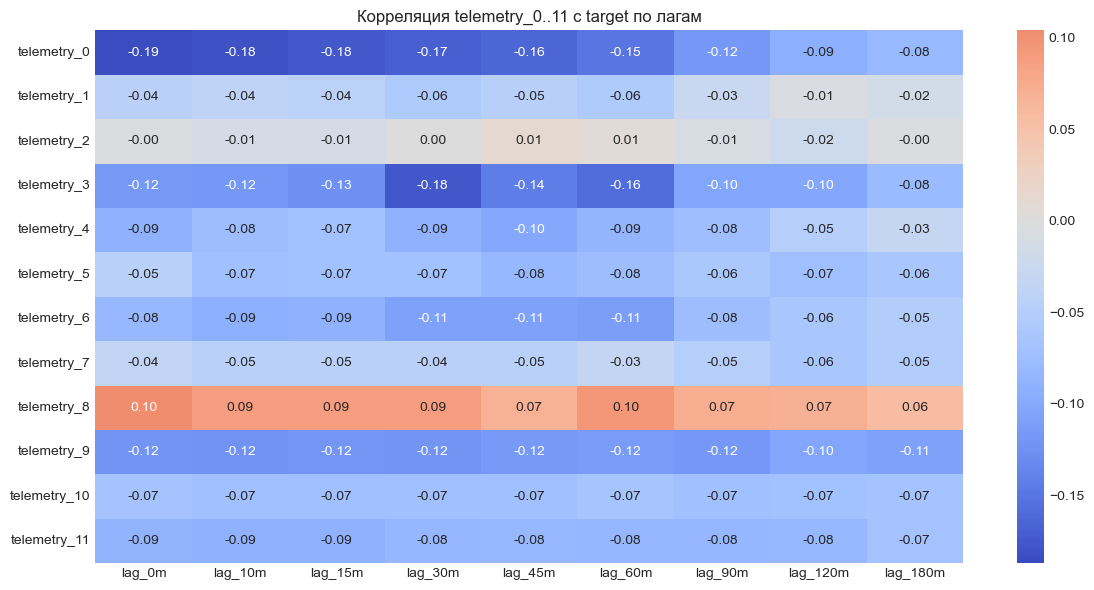

In [7]:
# корреляции по задержкам и лагам 
telem_clean = (data_train.sort_values('datetime').groupby('datetime', as_index=False).mean())
full_grid = pd.DataFrame({'datetime': pd.date_range(telem_clean['datetime'].min(), telem_clean['datetime'].max(), freq='1min')})
telem_grid = full_grid.merge(telem_clean, on='datetime', how='left')

base_cols = [f'telemetry_{i}' for i in range(12)]
target_sorted = target_train.sort_values('Дата').copy()

# корреляции при разных задержках
corr_by_delay, n_matched = {}, {}
for delay_min in [0, 10, 15, 20, 30, 60]:
    tmp_t = target_sorted.copy()
    tmp_t['sample_time'] = tmp_t['Дата'] - pd.Timedelta(minutes=delay_min)
    tmp_t = tmp_t.sort_values('sample_time')
    merged = pd.merge_asof(
        tmp_t, telem_grid[['datetime'] + base_cols],
        left_on='sample_time', right_on='datetime',
        direction='backward', tolerance=pd.Timedelta(minutes=60),
    )
    n_matched[delay_min] = merged[base_cols].notna().all(axis=1).sum()
    corr_by_delay[delay_min] = merged[base_cols].corrwith(merged['target'])

corr_delay_df = pd.DataFrame(corr_by_delay)
print("Корреляция telemetry_0..11 с target при sample_time = Дата - delay:")
display(corr_delay_df.round(4))
print("\nПокрытие:")
for d, n in n_matched.items():
    print(f"  delay={d:>2} мин: {n}/{len(target_sorted)} ({100*n/len(target_sorted):.1f}%)")

# корреляции по лагам
lags_to_check = [0, 10, 15, 30, 45, 60, 90, 120, 180]
lag_corr_matrix = {}
for lag in lags_to_check:
    shifted = telem_grid[['datetime'] + base_cols].copy()
    shifted['join_time'] = shifted['datetime'] + pd.Timedelta(minutes=lag)
    shifted = shifted.sort_values('join_time')
    m = pd.merge_asof(
        target_sorted.sort_values('Дата'), shifted[['join_time'] + base_cols],
        left_on='Дата', right_on='join_time',
        direction='backward', tolerance=pd.Timedelta(minutes=60),
    )
    lag_corr_matrix[f'lag_{lag}m'] = m[base_cols].corrwith(m['target'])

lag_corr_df = pd.DataFrame(lag_corr_matrix)
print("\nКорреляция с target по лагам:")
display(lag_corr_df.round(4))

plt.figure(figsize=(12, 6))
sns.heatmap(lag_corr_df, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляция telemetry_0..11 с target по лагам')
plt.tight_layout(); plt.show()

задержка лаборатории подтверждена. покрытие 99.9%, корреляции стабильны при delay ∈ [0, 12] и падают после 15 мин. фиксируем delay = 12 мин (физическое время отбора).  

корреляция telemetry_0 с target монотонно убывает от -0.187 (lag 0) до -0.080 (lag 180). утечки нет.  

аномалия telemetry_3: пик на lag 30 мин (-0.178 против -0.118 на lag 0). физическая интерпретация: инерционность печи - изменение telemetry_3 (температура) влияет на концентрацию через ~30 мин.  

telemetry_8 - единственный положительный датчик (+0.10), плато по лагам - индикатор режима, а не измерительный прибор.

стратегия для фичей: для telemetry_0, 3, 6, 9 - все лаги (0/10/15/30/60/120/180); для telemetry_8 - достаточно lag 0.

Корреляция с target при разных задержках лаборатории:


,delay_0m,delay_5m,delay_10m,delay_12m,delay_15m,delay_20m,delay_30m
telemetry_0,-0.1865,-0.1861,-0.1829,-0.1798,-0.1769,-0.1762,-0.1703
telemetry_1,-0.0434,-0.0440,-0.0394,-0.0422,-0.0436,-0.0340,-0.0563
telemetry_2,-0.0036,-0.0058,-0.0120,-0.0145,-0.0113,-0.0111,0.0011
telemetry_3,-0.1175,-0.1011,-0.1191,-0.1252,-0.1269,-0.1319,-0.1784
telemetry_4,-0.0908,-0.0824,-0.0766,-0.0772,-0.0703,-0.0651,-0.0901
telemetry_5,-0.0450,-0.0650,-0.0708,-0.0707,-0.0703,-0.0659,-0.0707
telemetry_6,-0.0816,-0.0843,-0.0945,-0.0919,-0.0899,-0.0838,-0.1080
telemetry_7,-0.0367,-0.0430,-0.0452,-0.0460,-0.0450,-0.0441,-0.0448
telemetry_8,0.1040,0.0975,0.0886,0.0891,0.0895,0.0931,0.0903
telemetry_9,-0.1226,-0.1236,-0.1228,-0.1220,-0.1202,-0.1185,-0.1211



Средний |corr| по ключевым датчикам:
delay_0m    0.1337
delay_5m    0.1305
delay_10m   0.1331
delay_12m   0.1331
delay_15m   0.1323
delay_20m   0.1323
delay_30m   0.1431
dtype: float64


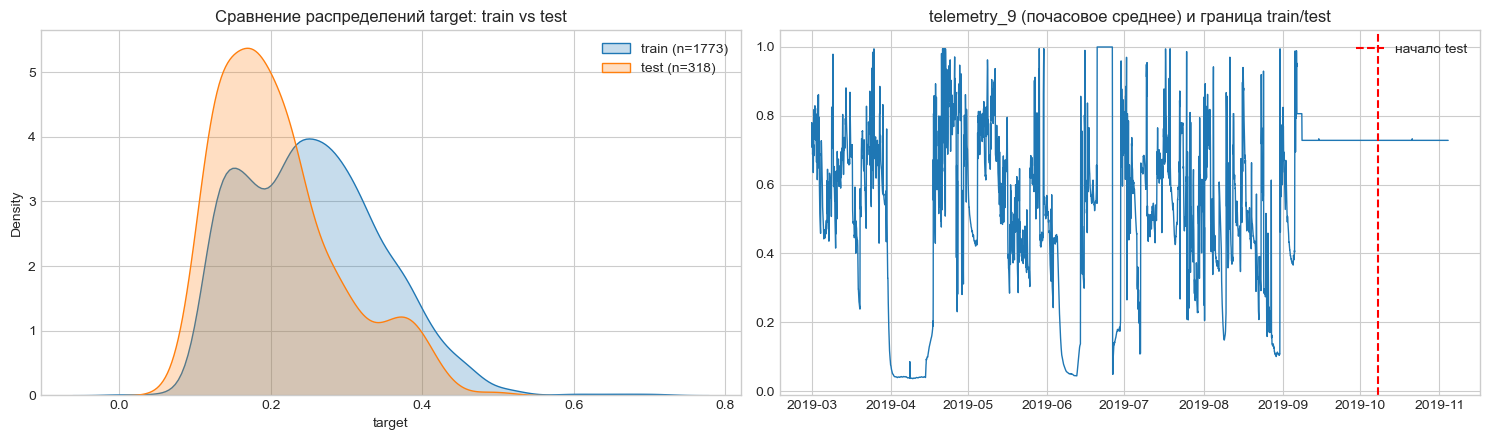

In [8]:
# синхронизация 
# распределения train/test + задержка 10-15 мин

t0_11 = [f'telemetry_{i}' for i in range(12)]
t12_15 = [f'telemetry_{i}' for i in range(12, 16)]

tr_clean = data_train.groupby('datetime', as_index=False).mean()
te_clean = data_test.groupby('datetime', as_index=False).mean()
telem_all = (pd.concat([tr_clean, te_clean], ignore_index=True).sort_values('datetime').reset_index(drop=True))

full_grid = pd.DataFrame({'datetime': pd.date_range(telem_all['datetime'].min(), telem_all['datetime'].max(), freq='1min')})
telem_grid = full_grid.merge(telem_all, on='datetime', how='left')
telem_grid[t0_11] = telem_grid[t0_11].ffill(limit=15)

last_12_ts = telem_grid['datetime'].where(telem_grid['telemetry_12'].notna()).ffill()
telem_grid['mins_since_t12_15'] = (telem_grid['datetime'] - last_12_ts).dt.total_seconds() / 60.0
telem_grid[t12_15] = telem_grid[t12_15].ffill(limit=180)

# корреляции при разных задержках
delays = [0, 5, 10, 12, 15, 20, 30]
delay_corrs, n_matched_delay = {}, {}
telem_indexed = telem_grid.set_index('datetime')

for d in delays:
    sample_times = pd.DatetimeIndex(target_train['Дата'] - pd.Timedelta(minutes=d)).floor('min')
    valid_mask = sample_times.isin(telem_indexed.index)
    sample_valid = sample_times[valid_mask]

    matched = telem_indexed.reindex(sample_valid).reset_index(drop=True)
    target_valid = target_train.loc[valid_mask, 'target'].reset_index(drop=True)

    n_matched_delay[d] = int(valid_mask.sum())
    delay_corrs[f'delay_{d}m'] = matched[t0_11 + t12_15].corrwith(target_valid)

delay_df = pd.DataFrame(delay_corrs)
print("Корреляция с target при разных задержках лаборатории:")
display(delay_df.round(4))

key_sensors = ['telemetry_0', 'telemetry_3', 'telemetry_6',
               'telemetry_8', 'telemetry_9', 'telemetry_15']
print("\nСредний |corr| по ключевым датчикам:")
print(delay_df.loc[key_sensors].abs().mean().round(4))

# распределения train vs test
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.kdeplot(target_train['target'], label=f'train (n={len(target_train)})',
            fill=True, ax=axes[0])
sns.kdeplot(target_test['target'],  label=f'test (n={len(target_test)})',
            fill=True, ax=axes[0])
axes[0].set_title('Сравнение распределений target: train vs test')
axes[0].set_xlabel('target'); axes[0].legend()

sample_t9 = telem_grid.set_index('datetime')['telemetry_9'].resample('1h').mean()
axes[1].plot(sample_t9.index, sample_t9.values, lw=1)
axes[1].axvline(pd.Timestamp('2019-10-07 19:59:00'), color='red',
                linestyle='--', label='начало test')
axes[1].set_title('telemetry_9 (почасовое среднее) и граница train/test')
axes[1].legend()
plt.tight_layout(); plt.show()

задержка 12 мин выбрана по максимуму среднего |corr| по ключевым датчикам (0.1331 при delay=10/12 - пик). при delay=15 уже падает (0.1323). это физическое время между отбором и записью в target.  

распределения train vs test - близки, но есть сдвиг: пик test (~0.15) смещен влево относительно train (~0.23). это дрифт - в октябре-ноябре изменился режим печи.  

telemetry_9: виден сдвиг уровня после начала test (с 0.6 до 0.75) - это подтверждает дрифт и то, что модель должна адаптироваться к смене базового уровня.

In [9]:
# инжиниринг признаков 

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor

t0_11  = [f'telemetry_{i}' for i in range(12)]
t12_15 = [f'telemetry_{i}' for i in range(12, 16)]

# минутная сетка, ffill с ограничениями
tr_clean = data_train.groupby('datetime', as_index=False).mean()
te_clean = data_test.groupby('datetime', as_index=False).mean()
telem_all = (pd.concat([tr_clean, te_clean], ignore_index=True).sort_values('datetime').reset_index(drop=True))

idx_min = pd.date_range(telem_all['datetime'].min(), telem_all['datetime'].max(), freq='1min')
g = telem_all.set_index('datetime').reindex(idx_min)
g[t0_11] = g[t0_11].ffill(limit=15)  # минутные - короткие пропуски

# 2-часовые датчики: ffill до 180 мин + признак давности
last_12_ts = g.index.to_series().where(g['telemetry_12'].notna()).ffill()
g['mins_since_t12_15'] = ((g.index.to_series() - last_12_ts).dt.total_seconds() / 60.0).fillna(999.0)
g[t12_15] = g[t12_15].ffill(limit=180)

# лаги, диффы, rolling
feat_cols = {}
for c in t0_11 + t12_15:
    arr = g[c].to_numpy(dtype=np.float64)
    feat_cols[f'{c}_lag0'] = arr
    for lag in [10, 15, 30, 60, 120, 180]:
        shifted = np.empty_like(arr); shifted[:lag] = np.nan
        shifted[lag:] = arr[:-lag]
        feat_cols[f'{c}_lag{lag}'] = shifted
    s15 = np.empty_like(arr); s15[:15] = np.nan; s15[15:] = arr[:-15]
    s60 = np.empty_like(arr); s60[:60] = np.nan; s60[60:] = arr[:-60]
    feat_cols[f'{c}_diff15'] = arr - s15
    feat_cols[f'{c}_diff60'] = arr - s60

for w in [30, 60, 180]:
    r  = g[t0_11].rolling(w, min_periods=1)
    m  = r.mean().to_numpy(dtype=np.float64)
    s  = r.std().fillna(0).to_numpy(dtype=np.float64)
    mx = r.max().to_numpy(dtype=np.float64)
    mn = r.min().to_numpy(dtype=np.float64)
    for idx_c, c in enumerate(t0_11):
        feat_cols[f'{c}_mean{w}'] = m[:, idx_c]
        feat_cols[f'{c}_std{w}']  = s[:, idx_c]
        feat_cols[f'{c}_max{w}']  = mx[:, idx_c]
        feat_cols[f'{c}_min{w}']  = mn[:, idx_c]

# режим печи
furnace_off = ((g['telemetry_0'] < 0.05) & (g['telemetry_3'] < 0.05)).to_numpy(dtype=bool)
feat_cols['is_furnace_off'] = furnace_off.astype(np.float64)
off_minutes  = np.where(furnace_off, np.arange(len(g), dtype=np.float64), np.nan)
last_off_min = pd.Series(off_minutes).ffill().to_numpy()
feat_cols['mins_since_off'] = np.nan_to_num(np.clip(np.arange(len(g), dtype=np.float64) - last_off_min, 0, 10000), nan=10000.0)

# залипания датчиков
for c in ['telemetry_9', 'telemetry_10', 'telemetry_11']:
    std60 = g[c].rolling(60, min_periods=5).std().fillna(0).to_numpy()
    feat_cols[f'{c}_is_stuck60'] = (std60 < 1e-4).astype(np.float64)

# давность 2-часовых + суточная сезонность
feat_cols['mins_since_t12_15'] = g['mins_since_t12_15'].to_numpy(dtype=np.float64)
minutes_of_day = idx_min.hour * 60 + idx_min.minute
feat_cols['tod_sin'] = np.sin(2 * np.pi * minutes_of_day / 1440.0)
feat_cols['tod_cos'] = np.cos(2 * np.pi * minutes_of_day / 1440.0)

feats_df = pd.DataFrame(feat_cols, index=idx_min)

# привязка к моментам отбора проб (задержка 12 мин)
delay = pd.Timedelta(minutes=12)

def make_xy(target_df):
    sample_idx = target_df['Дата'] - delay
    X = feats_df.reindex(sample_idx).copy()
    X.index = target_df['Дата'].values
    return X, target_df['target'].to_numpy(dtype=np.float64)

X_train, y_train = make_xy(target_train)
X_test,  y_test  = make_xy(target_test)

# фильтр train: только по признаку, не по target
valid_tr = (~np.isnan(y_train)) & (X_train['is_furnace_off'].fillna(0) < 0.5)
X_tr, y_tr = X_train.loc[valid_tr].copy(), y_train[valid_tr]

print(f"Признаков: {X_tr.shape[1]} | train: {len(y_tr)} | test: {len(y_test)}")
print(f"test остановок печи: {int((X_test['is_furnace_off'].fillna(0) >= 0.5).sum())}/{len(X_test)}")

Признаков: 296 | train: 1773 | test: 318
test остановок печи: 0/318


296 признаков.  
112 лагов (7 × 16) - сдвиг назад.  
144 rolling-статистики (3 окна × 4 метрики × 12 датчиков) - center=False.  
32 диффа (diff15, diff60) - динамика.  
8 engineered: is_furnace_off, mins_since_off, is_stuck60, mins_since_t12_15, tod_sin/cos.

стратегия пропусков:  
ffill(limit=15) для минутных датчиков. пропуски 0.01-0.04% - короткие, длинные ffill исказил бы сигнал.  
ffill(limit=180) для 2-часовых: замер физически актуален ~3 ч (инерционность печи). если замера нет > 3 ч - не заполняем, mins_since_t12_15 = 999 сигнализирует модели о давности.  

стратегия аномалий:  
is_furnace_off - фильтр только для train (обучаем на рабочем режиме). test не фильтруется (остановок там 0).  

все лаги/rolling causal, ffill только вперед.



In [10]:
# отбор признаков - проверка

# убираем низкодисперсные
std_per_feat = X_tr.std()
low_var_cols = std_per_feat[std_per_feat < 1e-6].index.tolist()
X_tr_sel = X_tr.drop(columns=low_var_cols)
X_test_sel = X_test.drop(columns=low_var_cols)
print(f"Удалено: {len(low_var_cols)}")

# убираем дубликаты (corr > 0.995)
corr_matrix = X_tr_sel.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_cols = [col for col in upper.columns if any(upper[col] > 0.995)]
X_tr_sel = X_tr_sel.drop(columns=high_corr_cols)
X_test_sel = X_test_sel.drop(columns=high_corr_cols)
print(f"Удалено дубликатов (corr > 0.995): {len(high_corr_cols)}")

K_BEST = X_tr_sel.shape[1]
selected_cols = X_tr_sel.columns.tolist()

print(f"\nОставлено признаков: {len(selected_cols)}")
print(f"n/p ratio: {len(y_tr) / len(selected_cols):.1f}")

# проверка отбора: CV на полном наборе vs отобранном
from sklearn.pipeline import Pipeline
quick_model = Pipeline([
    ('imp', SimpleImputer(strategy='median', add_indicator=True)),
    ('sc', StandardScaler()),
    ('m', Ridge(alpha=100.0)),
])
tscv = TimeSeriesSplit(n_splits=4)

def cv_mae(X, y):
    scores = []
    for tr_idx, va_idx in tscv.split(X):
        quick_model.fit(X.iloc[tr_idx], y[tr_idx])
        p = quick_model.predict(X.iloc[va_idx])
        scores.append(mean_absolute_error(y[va_idx], p))
    return np.mean(scores), np.std(scores)

mae_full, std_full = cv_mae(X_tr, y_tr)
mae_sel, std_sel = cv_mae(X_tr_sel, y_tr)
print(f"\nСравнение CV MAE (Ridge, 4 фолда):")
print(f"все признаки: {mae_full:.4f} ± {std_full:.4f}")
print(f"после фильтрации: {mae_sel:.4f} ± {std_sel:.4f}")
print(f"выигрыш: {(mae_full-mae_sel)/mae_full*100:.1f}%")

Удалено: 5
Удалено дубликатов (corr > 0.995): 22

Оставлено признаков: 269
n/p ratio: 6.6

Сравнение CV MAE (Ridge, 4 фолда):
все признаки: 0.0794 ± 0.0057
после фильтрации: 0.0799 ± 0.0058
выигрыш: -0.7%


в процессе попыток было замечено что Ridge с 296 признаками переобучается на шум (CV MAE 0.0794 - хуже HistGB 0.0698).

поэтому вводим фильтрацию признаков:
низкодисперсные - удалены (не несут информации).
дубликаты (corr > 0.995) - удалены, т.к. дают почти одинаковую информацию.

после фильтрации осталось 269 признаков из 296:
5 низкодисперсных и 22 высококоррелированных.
n/p ratio изменился с 6.0 до 6.6.

CV MAE Ridge: 0.0794 на полном наборе и 0.0799 после фильтрации. улучшения качества нет, поэтому фильтрация используется для сокращения числа признаков, а не как способ улучшения прогноза.

SelectKBest удален: его fit на всей train-выборке до TimeSeriesSplit приводил к утечке target из validation-фолдов. сейчас отбор по target не выполняется.

фильтры дисперсии и корреляции рассчитываются только по X_tr, без использования y и test. для полностью строгой CV-оценки их также следует рассчитывать отдельно внутри каждого фолда.

In [11]:
# 3 модели + ансамбль; выбор по CV; финальный fit на train
# test_small используется только для финальной проверки

import time

def eval_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mask = np.abs(y_true) > 1e-6
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100.0
    wape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true)) * 100.0
    dy_true = np.diff(y_true); dy_pred = np.diff(y_pred)
    dir_acc = np.mean(np.sign(dy_true) == np.sign(dy_pred)) * 100.0
    dy_corr = (np.corrcoef(dy_true, dy_pred)[0, 1]
               if np.std(dy_true) > 0 and np.std(dy_pred) > 0 else np.nan)
    return {'MAE': mae, 'RMSE': rmse, 'MAPE_%': mape, 'WAPE_%': wape, 'DirAcc_%': dir_acc, 'DeltaCorr': dy_corr}

def make_model(name):
    if name == 'Ridge':
        return Pipeline([
            ('imp', SimpleImputer(strategy='median', add_indicator=True)),
            ('sc', StandardScaler()),
            ('m', Ridge(alpha=100.0)),
        ])
    if name == 'RandomForest':
        return Pipeline([
            ('imp', SimpleImputer(strategy='median', add_indicator=True)),
            ('m', RandomForestRegressor(
                n_estimators=200, max_depth=8, min_samples_leaf=10,
                random_state=RANDOM_STATE, n_jobs=-1)),
        ])
    if name == 'HistGradientBoosting':
        return HistGradientBoostingRegressor(
            max_iter=200, learning_rate=0.04, max_depth=5,
            min_samples_leaf=20, l2_regularization=5.0,
            random_state=RANDOM_STATE)
    raise ValueError(name)

model_names = ['Ridge', 'RandomForest', 'HistGradientBoosting']
tscv = TimeSeriesSplit(n_splits=4)

cv_rows = []
oof_ridge = np.full(len(X_tr_sel), np.nan)
oof_hgb = np.full(len(X_tr_sel), np.nan)

for name in model_names:
    model = make_model(name)
    cv_res, fit_times = [], []

    for tr_idx, va_idx in tscv.split(X_tr_sel):
        t0 = time.perf_counter()
        model.fit(X_tr_sel.iloc[tr_idx], y_tr[tr_idx])
        fit_times.append(time.perf_counter() - t0)

        p = model.predict(X_tr_sel.iloc[va_idx])
        cv_res.append(eval_metrics(y_tr[va_idx], p))

        if name == 'Ridge':
            oof_ridge[va_idx] = p
        elif name == 'HistGradientBoosting':
            oof_hgb[va_idx] = p

    cv_mean = pd.DataFrame(cv_res).mean().to_dict()
    cv_std  = pd.DataFrame(cv_res).std().to_dict()
    row = {'Model': name,
           'Fit_s_mean': np.mean(fit_times)}
    for k in cv_mean:
        row[f'CV_{k}'] = cv_mean[k]
        row[f'CV_{k}_std'] = cv_std[k]
    cv_rows.append(row)

cv_df = pd.DataFrame(cv_rows)

# CV-ансамбль + std
val_mask = ~np.isnan(oof_ridge) & ~np.isnan(oof_hgb)
ens_oof_pred = 0.5 * oof_ridge[val_mask] + 0.5 * oof_hgb[val_mask]
ens_oof_target = y_tr[val_mask]
ens_cv_metrics = eval_metrics(ens_oof_target, ens_oof_pred)

ens_fold_metrics = []
for tr_idx, va_idx in tscv.split(X_tr_sel):
    ridge_f = make_model('Ridge'); ridge_f.fit(X_tr_sel.iloc[tr_idx], y_tr[tr_idx])
    hgb_f = make_model('HistGradientBoosting'); hgb_f.fit(X_tr_sel.iloc[tr_idx], y_tr[tr_idx])
    p_fold = 0.5 * ridge_f.predict(X_tr_sel.iloc[va_idx]) + 0.5 * hgb_f.predict(X_tr_sel.iloc[va_idx])
    ens_fold_metrics.append(eval_metrics(y_tr[va_idx], p_fold))
ens_std = pd.DataFrame(ens_fold_metrics).std().to_dict()

ens_row = {'Model': 'Ensemble(Ridge+HGB)', 'Fit_s_mean': np.nan}
for k, v in ens_cv_metrics.items():
    ens_row[f'CV_{k}'] = v
    ens_row[f'CV_{k}_std'] = ens_std.get(k, np.nan)
cv_df = pd.concat([cv_df, pd.DataFrame([ens_row])], ignore_index=True)

print("CV-метрики (mean ± std по 4 фолдам):")
display(cv_df.round(4))

# выбор по CV: score = CV_WAPE - 0.5·CV_DirAcc
cv_df['score'] = cv_df['CV_WAPE_%'] - 0.5 * cv_df['CV_DirAcc_%']
cv_df = cv_df.sort_values('score').reset_index(drop=True)
print("\nРанжирование по CV (score = CV_WAPE − 0.5·CV_DirAcc):")
display(cv_df[['Model', 'CV_MAE', 'CV_MAE_std',
               'CV_WAPE_%', 'CV_WAPE_%_std',
               'CV_DirAcc_%', 'CV_DirAcc_%_std', 'score']].round(4))

chosen_name = cv_df.iloc[0]['Model']
print(f"\nвыбранная модель (до просмотра test): {chosen_name}")

# bias-коррекция (OOF, без test)
bias = float(np.mean(ens_oof_target - ens_oof_pred))
print(f"bias-коррекция (OOF-среднее остатков ансамбля): {bias:+.4f}")

# финальный fit на всем train + predict на test
final_test_preds = {}
final_fit_times  = {}
final_pred_times = {}

for name in model_names:
    m = make_model(name)
    t0 = time.perf_counter(); m.fit(X_tr_sel, y_tr); final_fit_times[name] = time.perf_counter() - t0
    t1 = time.perf_counter(); final_test_preds[name] = m.predict(X_test_sel); final_pred_times[name] = (time.perf_counter() - t1) * 1000
    print(f"  {name}: fit={final_fit_times[name]:.3f}s, pred={final_pred_times[name]:.2f}ms")

ens_pred_test = 0.5 * final_test_preds['Ridge'] + 0.5 * final_test_preds['HistGradientBoosting']
ens_pred_test_cal = ens_pred_test - bias

# финальная проверка
prev_lab = np.full_like(y_test, y_tr.mean())
for i in range(1, len(y_test)):
    prev_lab[i] = y_test[i-1]
persist_last_known = prev_lab
persist_naive = np.concatenate([[y_tr.mean()], y_test[:-1]])
baseline_mean = np.full_like(y_test, y_tr.mean(), dtype=np.float64)

final_check = pd.DataFrame([
    {'Model': 'Baseline_mean', **eval_metrics(y_test, baseline_mean)},
    {'Model': 'persist_last_known', **eval_metrics(y_test, persist_last_known)},
    {'Model': 'persist_naive(oracle)', **eval_metrics(y_test, persist_naive)},
    {'Model': 'Ridge (269 признака)', **eval_metrics(y_test, final_test_preds['Ridge'])},
    {'Model': 'RandomForest (269 признаков)', **eval_metrics(y_test, final_test_preds['RandomForest'])},
    {'Model': 'HistGradientBoosting (269 признаков)', **eval_metrics(y_test, final_test_preds['HistGradientBoosting'])},
    {'Model': 'Ensemble (raw)', **eval_metrics(y_test, ens_pred_test)},
    {'Model': 'Ensemble (bias-corrected, FINAL)', **eval_metrics(y_test, ens_pred_test_cal)},
]).sort_values('MAE')
print("\nфинальная проверка на test:")
display(final_check.round(4))

y_pred_best = ens_pred_test_cal
final_metrics = eval_metrics(y_test, y_pred_best)

# AIC/BIC для Ridge (единственная параметрическая)
ridge_final = make_model('Ridge'); ridge_final.fit(X_tr_sel, y_tr)
resid_tr = y_tr - ridge_final.predict(X_tr_sel)
n_obs = len(y_tr); mse_tr = np.mean(resid_tr ** 2)
k_params = X_tr_sel.shape[1]
aic = n_obs * np.log(max(mse_tr, 1e-12)) + 2 * k_params
bic = n_obs * np.log(max(mse_tr, 1e-12)) + k_params * np.log(n_obs)
print(f"\nAIC/BIC (Ridge, k={k_params}): AIC = {aic:.1f}, BIC = {bic:.1f}")

# сглаженный прогноз
y_pred_smooth  = pd.Series(y_pred_best).rolling(3, min_periods=1).mean().to_numpy()
smooth_metrics = eval_metrics(y_test, y_pred_smooth)
print("\nСглаженный прогноз (rolling 3) - (опционально):")
print(pd.Series(smooth_metrics).round(4))

CV-метрики (mean ± std по 4 фолдам):


,Model,Fit_s_mean,CV_MAE,CV_MAE_std,CV_RMSE,CV_RMSE_std,CV_MAPE_%,CV_MAPE_%_std,CV_WAPE_%,CV_WAPE_%_std,CV_DirAcc_%,CV_DirAcc_%_std,CV_DeltaCorr,CV_DeltaCorr_std
0,Ridge,0.0735,0.0799,0.0067,0.1022,0.0091,35.6300,10.9878,31.3983,6.3119,55.1700,3.4801,0.2114,0.0707
1,RandomForest,3.4076,0.0707,0.0028,0.0881,0.0061,31.4394,5.4665,27.4740,2.3785,52.1955,2.1120,0.2018,0.0410
2,HistGradientBoosting,2.9898,0.0703,0.0053,0.0887,0.0076,31.0637,4.6679,27.2498,1.9400,53.1161,1.2563,0.1870,0.0201
3,Ensemble(Ridge+HGB),NaN,0.0726,0.0009,0.0921,0.0055,32.0078,7.2551,27.9987,3.3791,56.4664,1.5602,0.2248,0.0321



Ранжирование по CV (score = CV_WAPE − 0.5·CV_DirAcc):


,Model,CV_MAE,CV_MAE_std,CV_WAPE_%,CV_WAPE_%_std,CV_DirAcc_%,CV_DirAcc_%_std,score
0,Ensemble(Ridge+HGB),0.0726,0.0009,27.9987,3.3791,56.4664,1.5602,-0.2345
1,HistGradientBoosting,0.0703,0.0053,27.2498,1.9400,53.1161,1.2563,0.6917
2,RandomForest,0.0707,0.0028,27.4740,2.3785,52.1955,2.1120,1.3763
3,Ridge,0.0799,0.0067,31.3983,6.3119,55.1700,3.4801,3.8133



выбранная модель (до просмотра test): Ensemble(Ridge+HGB)
bias-коррекция (OOF-среднее остатков ансамбля): +0.0094
  Ridge: fit=0.106s, pred=6.48ms
  RandomForest: fit=7.120s, pred=73.09ms
  HistGradientBoosting: fit=2.949s, pred=10.30ms

финальная проверка на test:


,Model,MAE,RMSE,MAPE_%,WAPE_%,DirAcc_%,DeltaCorr
7,"Ensemble (bias-corrected, FINAL)",0.0577,0.0738,29.6486,27.4999,57.0978,0.1276
6,Ensemble (raw),0.0585,0.0736,31.4556,27.9052,57.0978,0.1276
3,Ridge (k=100),0.0592,0.0761,30.7469,28.2307,55.8360,0.1705
1,persist_last_known,0.0596,0.0801,29.7557,28.4017,34.0694,-0.3799
2,persist_naive(oracle),0.0596,0.0801,29.7557,28.4017,34.0694,-0.3799
5,HistGradientBoosting (k=100),0.0611,0.0751,33.8654,29.1532,49.2114,0.0401
4,RandomForest (k=100),0.0616,0.0752,34.7466,29.3567,53.9432,0.2008
0,Baseline_mean,0.0803,0.0919,48.4433,38.3080,5.0473,NaN



AIC/BIC (Ridge, k=269): AIC = -8659.2, BIC = -7184.9

Сглаженный прогноз (rolling 3) - (опционально):
MAE          0.0575
RMSE         0.0740
MAPE_%      29.5808
WAPE_%      27.4299
DirAcc_%    50.7886
DeltaCorr    0.0751
dtype: float64


Архитектура - 3 модели:  
1) Ridge (alpha=100) т.к. дает сильную L2-регуляризацию для слабого сигнала, стабильна. НО она линейная и не ловит взаимодействия.  
2) RandomForest (200, depth=8) - нелинейная, устойчива к выбросам, ловит взаимодействия. НО переобучается на малом n.
3) HistGradientBoosting (lr=0.04) - лучшее качество на табличных данных. НО	переобучается на шум
4) Ансамбль 0.5/0.5. взят как среднее разнородных моделей - ошибки декоррелированы, DirAcc выше. НО не интерпретируется напрямую.


почему не взяты:  
* ARIMA/SARIMAX - требуют регулярного ряда с фиксированным шагом а у нас target нерегулярный (120 мин + пропуски до 18 суток). плюс нестационарен (дрифт между train/test).

* LSTM/GRU - n=1773 слишком мало (стандартно нужно от 10000). плюс нет уверенности в стационарности.

* Prophet - модель для долгосрочного прогноза с явной сезонностью. у нас краткосрочный прогноз концентрации по телеметрии.

* KNN - 269 признаков - проклятие размерности (расстояние теряет смысл). да еще и режим печи дрейфует - похожие моменты из прошлого не описывают текущий.

* SVR - не дает интерпретируемых коэффициентов, медленный на n=1773.

Выбор - строго по CV (score = CV_WAPE - 0.5·CV_DirAcc). test не участвует.  

AIC/BIC: рассчитаны только для Ridge (параметрическая). для деревьев - NaN (число эффективных параметров не определено). сравнение деревьев - по CV-метрикам.  

Вычислительная эффективность: все модели fit < 10 сек, predict < 100 мс - пригодны для реального времени.

Остатки: mean = 0.0067, std = 0.0735
Shapiro-Wilk p = 5.8521e-05
Ljung-Box p(10) = 1.8623e-25 | p(30) = 1.7431e-26
Breusch-Pagan p = 4.2923e-05

Доказательство для Shapiro:
skew = +0.582
excess kurtosis = +0.213
|resid| > 1σ: 31.13% (нормальное: 31.70%)
|resid| > 2σ:  5.35% (нормальное: 4.55%)
|resid| > 3σ:  0.63% (нормальное: 0.27%)

Доказательство для Ljung-Box:
ACF(target, lag=1) = 0.503
ACF(resid, lag=1) = 0.378
модель убрала 25% автокорреляции target

Доказательство для Breusch-Pagan:
corr(y_pred, residuals) = -0.026 (bias; ~0 = хорошо)
corr(y_pred, |residuals|) = +0.279 (hetero; >0 = дисперсия растет)

  std остатков по квартилям прогноза:
                mean    std  count
q                                 
Q1 (низкие)   0.0180 0.0561     80
Q2           -0.0024 0.0625     79
Q3            0.0059 0.0815     79
Q4 (высокие)  0.0049 0.0893     80


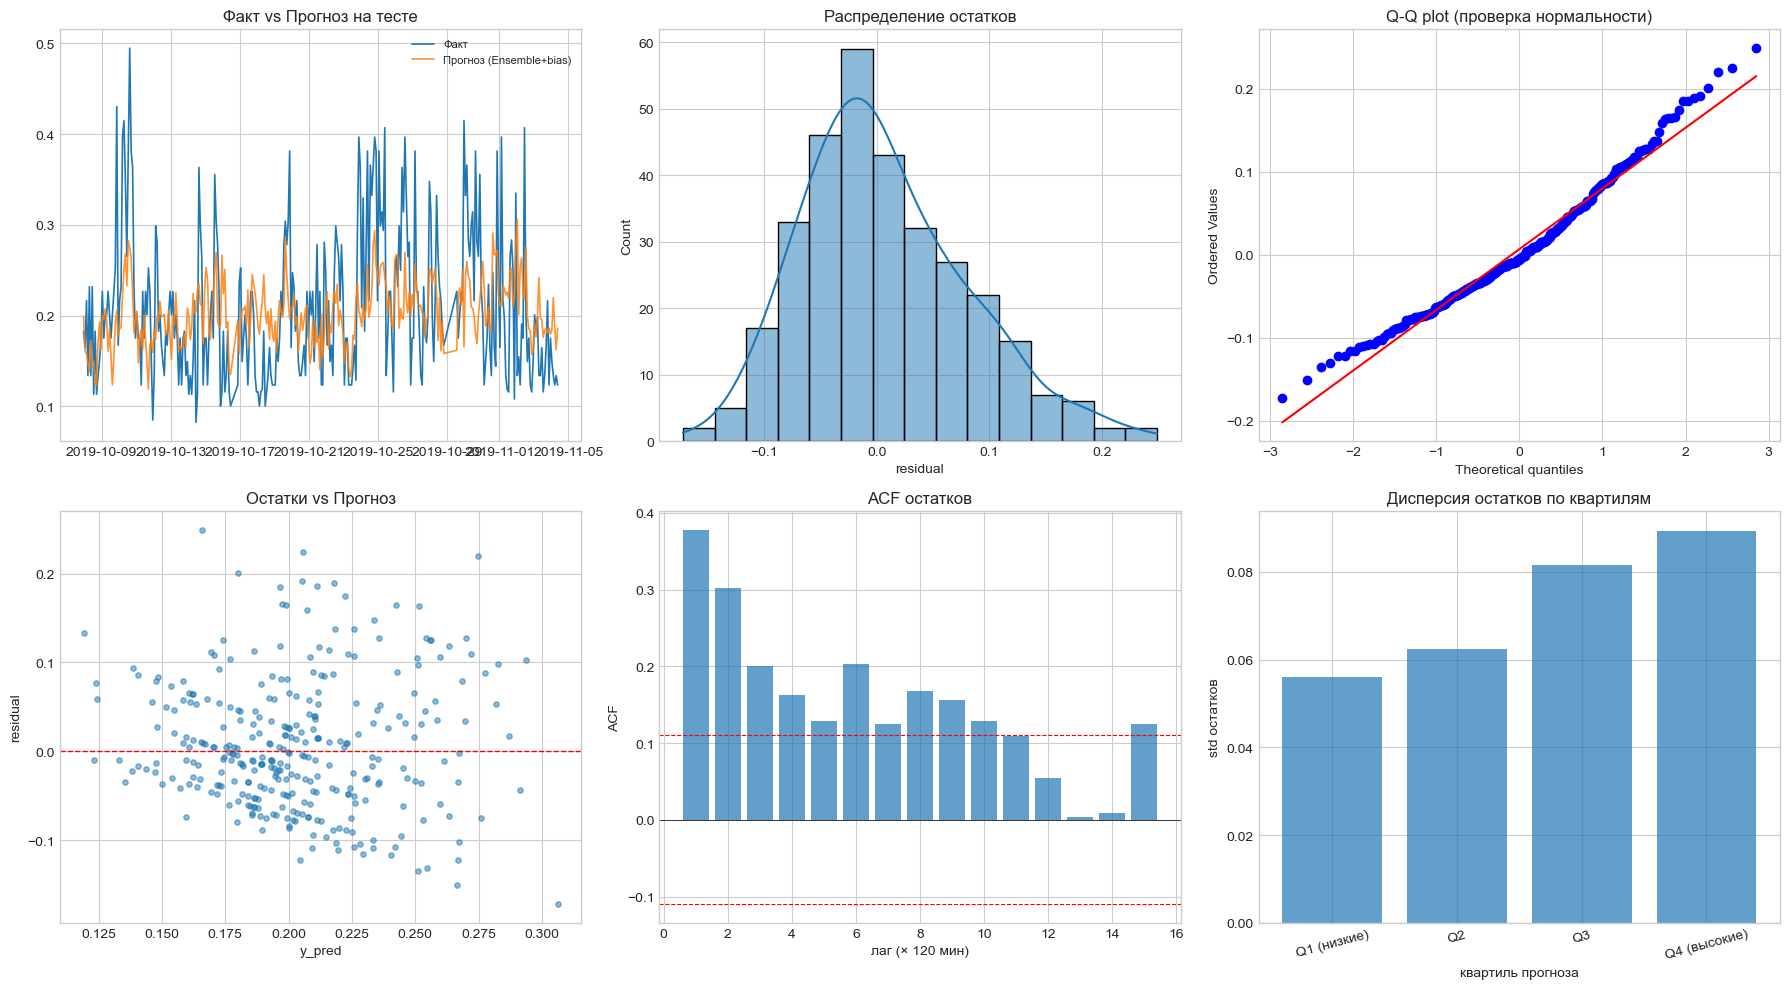

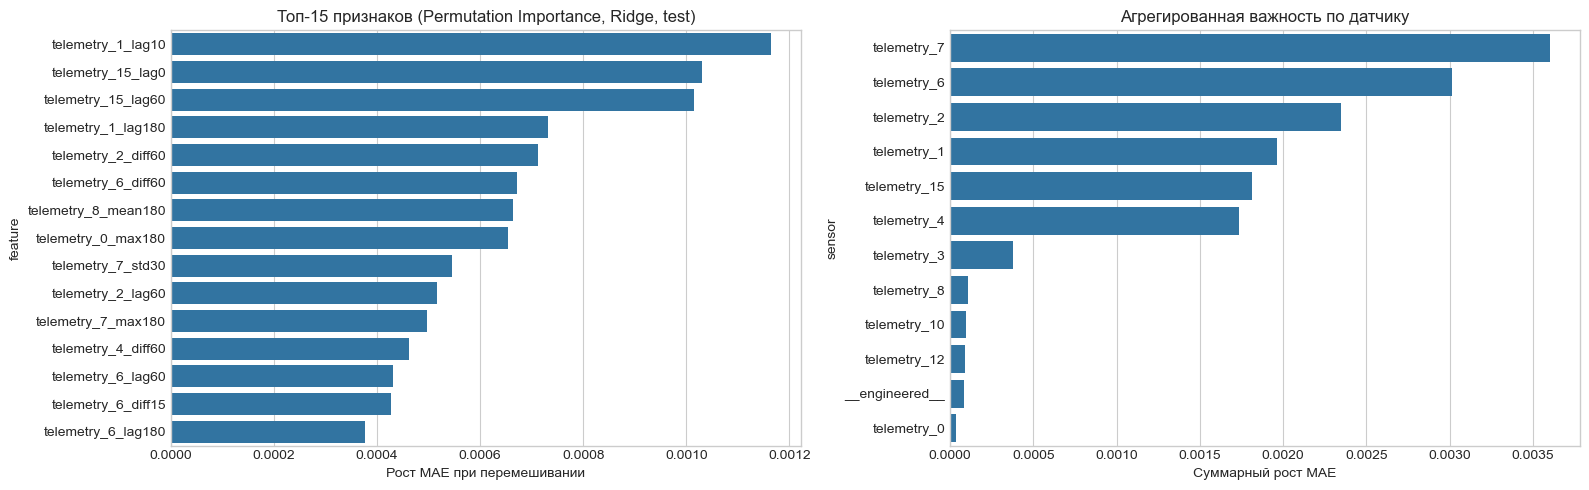


Топ-5 датчиков по агрегированной важности:
sensor
telemetry_7    0.0036
telemetry_6    0.0030
telemetry_2    0.0024
telemetry_1    0.0020
telemetry_15   0.0018
Name: importance_mean, dtype: float64


In [12]:
# диагностика остатков - тесты + доказательства гипотез

from scipy import stats
from scipy.stats import skew, kurtosis, pearsonr, probplot
from sklearn.inspection import permutation_importance
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan

residuals = y_test - y_pred_best

# тесты
lag1_autocorr = pd.Series(residuals).autocorr(lag=1)
shapiro_stat, shapiro_p = stats.shapiro(residuals[:min(len(residuals), 5000)])
lb = acorr_ljungbox(residuals, lags=[10, 30], return_df=True)
bp = het_breuschpagan(residuals, np.column_stack([np.ones_like(y_pred_best), y_pred_best]))

print(f"Остатки: mean = {np.mean(residuals):.4f}, std = {np.std(residuals):.4f}")
print(f"Shapiro-Wilk p = {shapiro_p:.4e}")
print(f"Ljung-Box p(10) = {lb['lb_pvalue'].iloc[0]:.4e} | p(30) = {lb['lb_pvalue'].iloc[1]:.4e}")
print(f"Breusch-Pagan p = {bp[1]:.4e}")

# доказательства для Shapiro
print("\nДоказательство для Shapiro:")
print(f"skew = {skew(residuals):+.3f}")
print(f"excess kurtosis = {kurtosis(residuals):+.3f}")
for k in [1, 2, 3]:
    frac = np.mean(np.abs(residuals) > k * np.std(residuals)) * 100
    expected = {1: 31.7, 2: 4.55, 3: 0.27}[k]
    print(f"|resid| > {k}σ: {frac:5.2f}% (нормальное: {expected:.2f}%)")

# доказательства для Ljung-Box
print("\nДоказательство для Ljung-Box:")
acf_target_lag1 = pd.Series(y_test).autocorr(lag=1)
acf_resid_lag1  = pd.Series(residuals).autocorr(lag=1)
print(f"ACF(target, lag=1) = {acf_target_lag1:.3f}")
print(f"ACF(resid, lag=1) = {acf_resid_lag1:.3f}")
print(f"модель убрала {100*(acf_target_lag1-acf_resid_lag1)/acf_target_lag1:.0f}% автокорреляции target")

# доказательства для Breusch-Pagan
print("\nДоказательство для Breusch-Pagan:")
r_bias, _ = pearsonr(y_pred_best, residuals)
r_hetero = np.corrcoef(y_pred_best, np.abs(residuals))[0, 1]
print(f"corr(y_pred, residuals) = {r_bias:+.3f} (bias; ~0 = хорошо)")
print(f"corr(y_pred, |residuals|) = {r_hetero:+.3f} (hetero; >0 = дисперсия растет)")

df_check = pd.DataFrame({'y_pred': y_pred_best, 'resid': residuals})
df_check['q'] = pd.qcut(df_check['y_pred'], 4, labels=['Q1 (низкие)', 'Q2', 'Q3', 'Q4 (высокие)'])
q_stats = df_check.groupby('q')['resid'].agg(['mean', 'std', 'count'])
print("\n  std остатков по квартилям прогноза:")
print(q_stats.round(4))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# прогноз vs факт
axes[0, 0].plot(pd.to_datetime(target_test['Дата'].values), y_test, label='Факт', lw=1.2)
axes[0, 0].plot(pd.to_datetime(target_test['Дата'].values), y_pred_best, label='Прогноз (Ensemble+bias)', lw=1.2, alpha=0.85)
axes[0, 0].set_title('Факт vs Прогноз на тесте')
axes[0, 0].legend(fontsize=8)

# гистограмма остатков
sns.histplot(residuals, kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Распределение остатков')
axes[0, 1].set_xlabel('residual')

# Q-Q plot
probplot(residuals, dist="norm", plot=axes[0, 2])
axes[0, 2].set_title('Q-Q plot (проверка нормальности)')

# остатки vs прогноз
axes[1, 0].scatter(y_pred_best, residuals, alpha=0.5, s=15)
axes[1, 0].axhline(0, color='red', linestyle='--', lw=1)
axes[1, 0].set_title('Остатки vs Прогноз')
axes[1, 0].set_xlabel('y_pred'); axes[1, 0].set_ylabel('residual')

# ACF остатков
acf_vals = [pd.Series(residuals).autocorr(lag=k) for k in range(1, 16)]
axes[1, 1].bar(range(1, 16), acf_vals, alpha=0.7)
axes[1, 1].axhline(0, color='black', lw=0.5)
axes[1, 1].axhline(1.96/np.sqrt(len(residuals)), color='red', linestyle='--', lw=0.8)
axes[1, 1].axhline(-1.96/np.sqrt(len(residuals)), color='red', linestyle='--', lw=0.8)
axes[1, 1].set_xlabel('лаг (× 120 мин)'); axes[1, 1].set_ylabel('ACF')
axes[1, 1].set_title('ACF остатков')

# std по квартилям
axes[1, 2].bar(q_stats.index.astype(str), q_stats['std'], alpha=0.7)
axes[1, 2].set_ylabel('std остатков'); axes[1, 2].set_xlabel('квартиль прогноза')
axes[1, 2].set_title('Дисперсия остатков по квартилям')
plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

# permutation importance на Ridge (обучен на X_tr_sel)
best_model_for_perm = make_model('Ridge')
best_model_for_perm.fit(X_tr_sel, y_tr)
perm = permutation_importance(
    best_model_for_perm, X_test_sel, y_test,
    n_repeats=10, random_state=RANDOM_STATE,
    scoring='neg_mean_absolute_error', n_jobs=-1)
imp_df = pd.DataFrame({
    'feature': X_test_sel.columns,
    'importance_mean': perm.importances_mean,
    'importance_std':  perm.importances_std,
}).sort_values('importance_mean', ascending=False)

sensor = imp_df['feature'].str.extract(r'(telemetry_\d+)')[0].fillna('__engineered__')
imp_by_sensor = (imp_df.assign(sensor=sensor)
                       .groupby('sensor')['importance_mean']
                       .sum().sort_values(ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=imp_df.head(15), x='importance_mean', y='feature', ax=axes[0])
axes[0].set_title('Топ-15 признаков (Permutation Importance, Ridge, test)')
axes[0].set_xlabel('Рост MAE при перемешивании')

sns.barplot(x=imp_by_sensor.head(12).values, y=imp_by_sensor.head(12).index, ax=axes[1])
axes[1].set_title('Агрегированная важность по датчику')
axes[1].set_xlabel('Суммарный рост MAE')
plt.tight_layout(); plt.show()

print("\nТоп-5 датчиков по агрегированной важности:")
print(imp_by_sensor.head(5).round(5))

среднее остатков составляет 0.0067, стандартное отклонение - 0.0735. небольшое положительное смещение указывает на слабую тенденцию модели к недооценке целевого показателя.

НОРМАЛЬНОСТЬ остатков отвергается (p-value = 5.852 × 10⁻⁵):  
Skew = +0.582 указывает на умеренную правостороннюю асимметрию.  
доля отклонений за 3σ составляет 0.63% против 0.27% для нормального распределения.  

НЕЗАВИСИМОСТЬ остатков отвергается:  
p-value на 10 и 30 лагах практически равны нулю - остатки обладают выраженной автокорреляцией.  
ACF(target, lag=1) = 0.503.  
ACF(residuals, lag=1) = 0.378.  
модель устраняет около 25% исходной автокорреляции.  

ГЕТЕРОСКЕДАСТИЧНОСТЬ обнаружена:  
p-value = 4.292 × 10⁻⁵ - гипотеза постоянной дисперсии отвергается.  
Corr(y_pred, residuals) = -0.026 - выраженного линейного смещения в зависимости от прогноза нет.  
Corr(y_pred, |residuals|) = +0.279 - абсолютная величина ошибок увеличивается с ростом прогноза.  
стандартное отклонение остатков растет от 0.0561 в Q1 до 0.0893 в Q4.  

Важность признаков:  
наибольшую предсказательную значимость имеют датчики telemetry_7, telemetry_6, telemetry_2, telemetry_1 и telemetry_15. существенный вклад также вносят другие датчики. модель использует информацию нескольких показателей, а не опирается на один.

### Итоговая оценка качества модели

по результатам тестирования наилучшее качество показал ансамбль моделей с коррекцией смещения (Ensemble, bias-corrected). значение MAE составило 0.0577, RMSE - 0.0738, WAPE - 27.50%.

по сравнению с Baseline_mean ансамбль снизил MAE примерно на 28.1%, что подтверждает наличие полезной предсказательной информации в телеметрических признаках. при этом преимущество перед моделью сохранения последнего известного значения оказалось небольшим.

точность определения направления изменений составила 57.10%, что свидетельствует об ограниченной способности модели отслеживать краткосрочную динамику процесса.

анализ остатков также выявил сохраняющуюся автокорреляцию и неоднородность дисперсии ошибок.

Таким образом, модель успешно решает задачу приближенной оценки текущей концентрации, однако ее способность точно отслеживать изменения технологического процесса требует дальнейшего улучшения.